In [5]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.preprocessing import LabelEncoder
from sklearn.model_selection import train_test_split
from imblearn.over_sampling import SMOTE
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score,confusion_matrix,classification_report
from xgboost import XGBClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.model_selection import GridSearchCV
from sklearn.model_selection import RandomizedSearchCV

In [6]:
#  pip install scikit-learn==1.2.2

In [7]:
#  pip install --upgrade xgboost scikit-learn


In [8]:
df=pd.read_csv("aug_train.csv")

# EDA

In [9]:
df

,enrollee_id,city,city_development_index,gender,relevent_experience,enrolled_university,education_level,major_discipline,experience,company_size,company_type,last_new_job,training_hours,target
0,8949,city_103,0.920,Male,Has relevent experience,no_enrollment,Graduate,STEM,>20,NaN,NaN,1,36,1.0
1,29725,city_40,0.776,Male,No relevent experience,no_enrollment,Graduate,STEM,15,50-99,Pvt Ltd,>4,47,0.0
2,11561,city_21,0.624,NaN,No relevent experience,Full time course,Graduate,STEM,5,NaN,NaN,never,83,0.0
3,33241,city_115,0.789,NaN,No relevent experience,NaN,Graduate,Business Degree,<1,NaN,Pvt Ltd,never,52,1.0
4,666,city_162,0.767,Male,Has relevent experience,no_enrollment,Masters,STEM,>20,50-99,Funded Startup,4,8,0.0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
19153,7386,city_173,0.878,Male,No relevent experience,no_enrollment,Graduate,Humanities,14,NaN,NaN,1,42,1.0
19154,31398,city_103,0.920,Male,Has relevent experience,no_enrollment,Graduate,STEM,14,NaN,NaN,4,52,1.0
19155,24576,city_103,0.920,Male,Has relevent experience,no_enrollment,Graduate,STEM,>20,50-99,Pvt Ltd,4,44,0.0
19156,5756,city_65,0.802,Male,Has relevent experience,no_enrollment,High School,NaN,<1,500-999,Pvt Ltd,2,97,0.0


In [10]:
df.shape

(19158, 14)

There are 14650 rows and 14 features.

In [11]:
df.head()

,enrollee_id,city,city_development_index,gender,relevent_experience,enrolled_university,education_level,major_discipline,experience,company_size,company_type,last_new_job,training_hours,target
0,8949,city_103,0.920,Male,Has relevent experience,no_enrollment,Graduate,STEM,>20,NaN,NaN,1,36,1.0
1,29725,city_40,0.776,Male,No relevent experience,no_enrollment,Graduate,STEM,15,50-99,Pvt Ltd,>4,47,0.0
2,11561,city_21,0.624,NaN,No relevent experience,Full time course,Graduate,STEM,5,NaN,NaN,never,83,0.0
3,33241,city_115,0.789,NaN,No relevent experience,NaN,Graduate,Business Degree,<1,NaN,Pvt Ltd,never,52,1.0
4,666,city_162,0.767,Male,Has relevent experience,no_enrollment,Masters,STEM,>20,50-99,Funded Startup,4,8,0.0


In [12]:
df.tail()

,enrollee_id,city,city_development_index,gender,relevent_experience,enrolled_university,education_level,major_discipline,experience,company_size,company_type,last_new_job,training_hours,target
19153,7386,city_173,0.878,Male,No relevent experience,no_enrollment,Graduate,Humanities,14,NaN,NaN,1,42,1.0
19154,31398,city_103,0.920,Male,Has relevent experience,no_enrollment,Graduate,STEM,14,NaN,NaN,4,52,1.0
19155,24576,city_103,0.920,Male,Has relevent experience,no_enrollment,Graduate,STEM,>20,50-99,Pvt Ltd,4,44,0.0
19156,5756,city_65,0.802,Male,Has relevent experience,no_enrollment,High School,NaN,<1,500-999,Pvt Ltd,2,97,0.0
19157,23834,city_67,0.855,NaN,No relevent experience,no_enrollment,Primary School,NaN,2,NaN,NaN,1,127,0.0


In [13]:
df.columns

Index(['enrollee_id', 'city', 'city_development_index', 'gender',
       'relevent_experience', 'enrolled_university', 'education_level',
       'major_discipline', 'experience', 'company_size', 'company_type',
       'last_new_job', 'training_hours', 'target'],
      dtype='object')

In [14]:
df.nunique()

,0
enrollee_id,19158
city,123
city_development_index,93
gender,3
relevent_experience,2
enrolled_university,3
education_level,5
major_discipline,6
experience,22
company_size,8


In [15]:
df.dtypes

,0
enrollee_id,int64
city,object
city_development_index,float64
gender,object
relevent_experience,object
enrolled_university,object
education_level,object
major_discipline,object
experience,object
company_size,object


There are 3 numeric and 10 categorical feature in independent features and dependent features has a numeric datatypes.

In [16]:
df.isna().sum()

,0
enrollee_id,0
city,0
city_development_index,0
gender,4508
relevent_experience,0
enrolled_university,386
education_level,460
major_discipline,2813
experience,65
company_size,5938


There are null values in gender, enrolled_university, education_level, major_discipline, experince, company_size, company_type,
last_new_jobs. total of 9 features.

In [17]:
# Mapping
experience_mapping = {
    '<1': 0, '1': 1, '2': 2, '3': 3, '4': 4, '5': 5, '6': 6, '7': 7,
    '8': 8, '9': 9, '10': 10, '11': 11, '12': 12, '13': 13, '14': 14,
    '15': 15, '16': 16, '17': 17, '18': 18, '19': 19, '20': 20, '>20': 21
}

# mapping is done on the experience
df['experience'] = df['experience'].map(experience_mapping)

# the missing values are feeling with median
df['experience'] = df['experience'].fillna(df['experience'].median())

Mapping is done to feature experience

In [18]:
categorical_cols = ['company_type', 'company_size', 'gender',
                    'major_discipline', 'education_level',
                    'last_new_job', 'enrolled_university']
for col in categorical_cols:
    df[col] = df[col].fillna('Unknown')  #

filling the all null values with words unknown

In [19]:
df.isna().sum()

,0
enrollee_id,0
city,0
city_development_index,0
gender,0
relevent_experience,0
enrolled_university,0
education_level,0
major_discipline,0
experience,0
company_size,0


In [20]:
df.shape

(19158, 14)

In [21]:
df.describe()

,enrollee_id,city_development_index,experience,training_hours,target
count,19158.000000,19158.000000,19158.000000,19158.000000,19158.000000
mean,16875.358179,0.828848,10.096409,65.366896,0.249348
std,9616.292592,0.123362,6.765820,60.058462,0.432647
min,1.000000,0.448000,0.000000,1.000000,0.000000
25%,8554.250000,0.740000,4.000000,23.000000,0.000000
50%,16982.500000,0.903000,9.000000,47.000000,0.000000
75%,25169.750000,0.920000,16.000000,88.000000,0.000000
max,33380.000000,0.949000,21.000000,336.000000,1.000000


In [22]:
df.duplicated().sum()

np.int64(0)

In [23]:
df['target'].value_counts()

,count
target,
0.0,14381
1.0,4777


As the value counts of target show that the data is imbalanced. so we are doing Oversampling for best accuracy

In [24]:
import  seaborn as sns

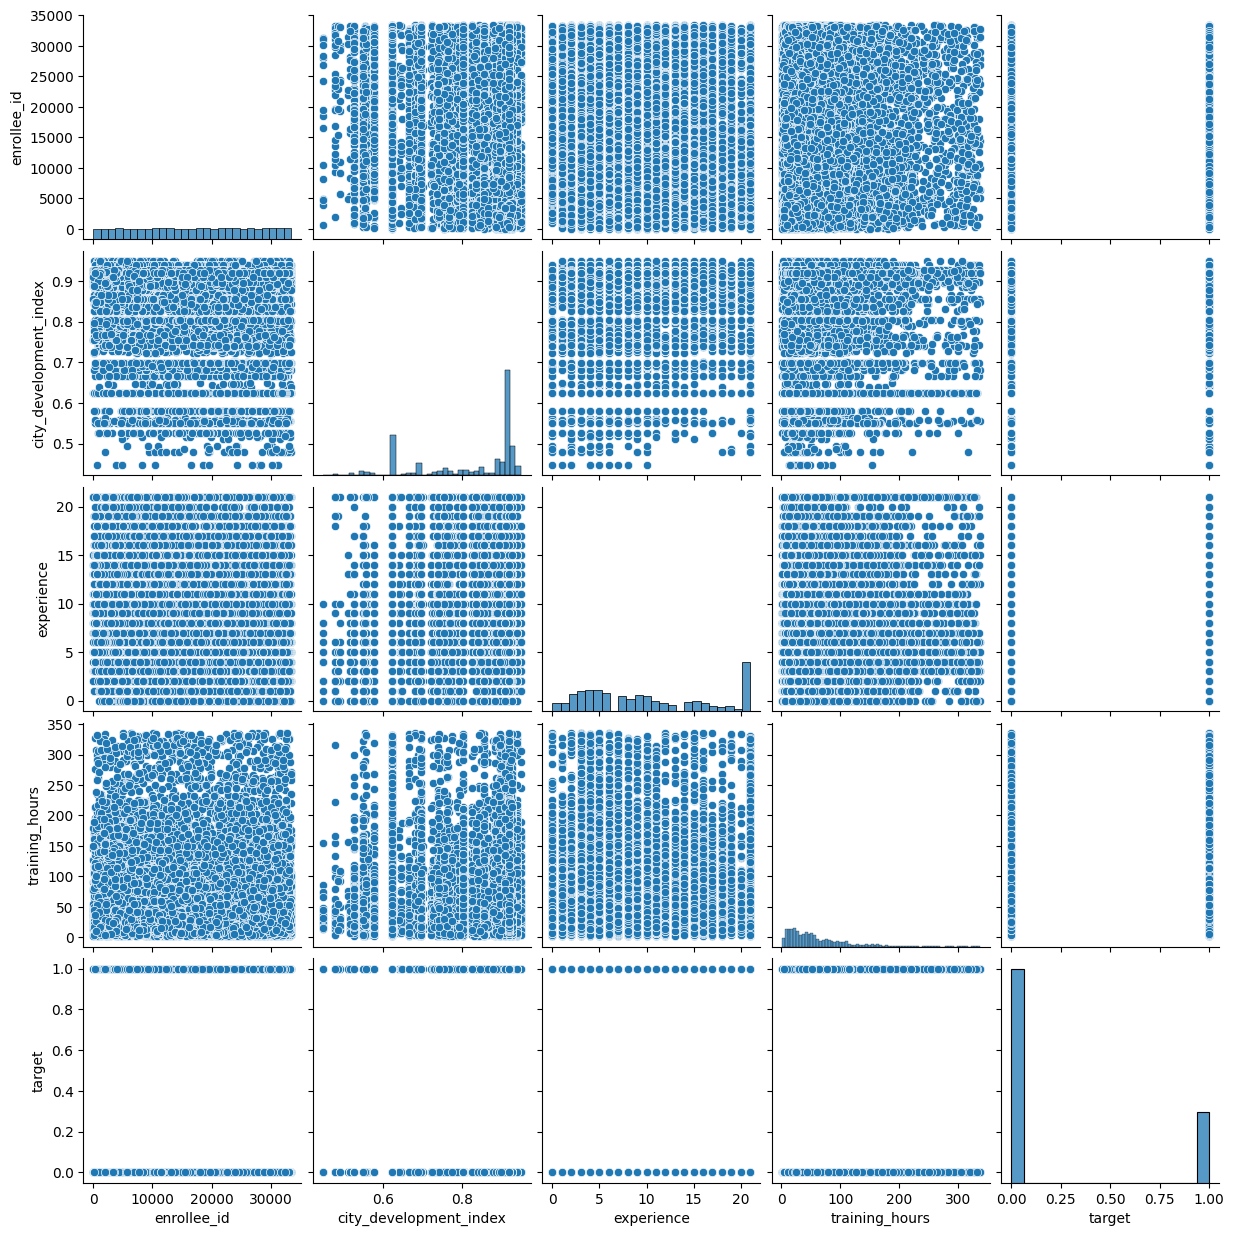

In [25]:
sns.pairplot(df)

In [26]:
num = df.select_dtypes(include='number')
co =  num.corr()

In [27]:
co

,enrollee_id,city_development_index,experience,training_hours,target
enrollee_id,1.000000,-0.040455,-0.035395,0.000998,0.049475
city_development_index,-0.040455,1.000000,0.333368,0.001920,-0.341665
experience,-0.035395,0.333368,1.000000,0.000848,-0.176465
training_hours,0.000998,0.001920,0.000848,1.000000,-0.021577
target,0.049475,-0.341665,-0.176465,-0.021577,1.000000


<Axes: >

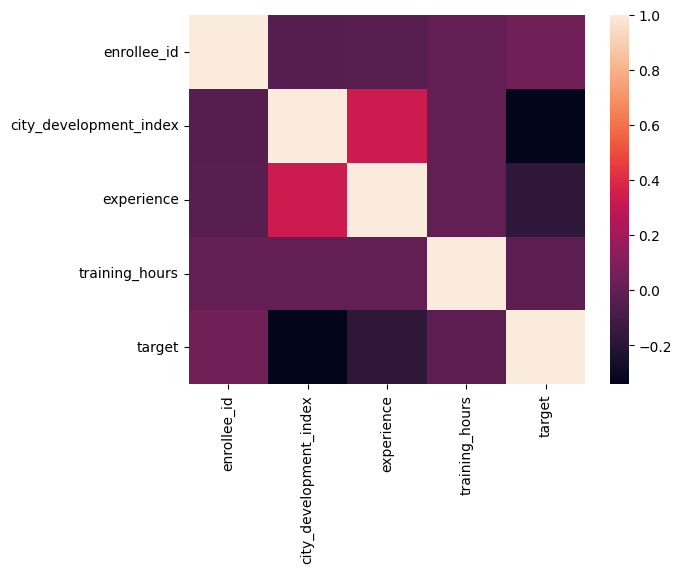

In [28]:
sns.heatmap(co)

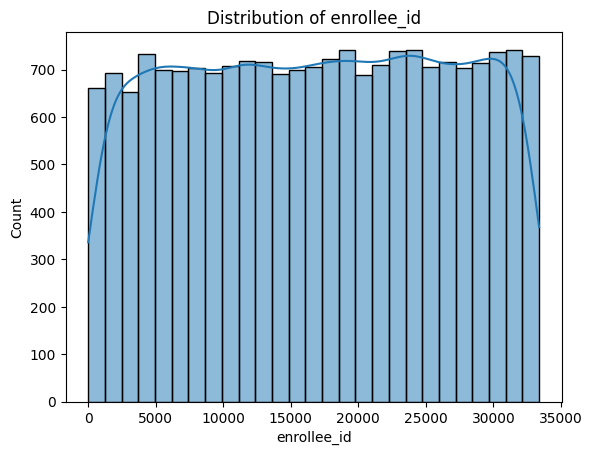

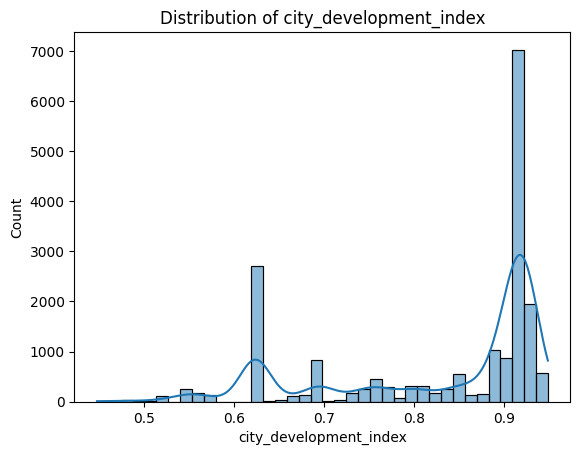

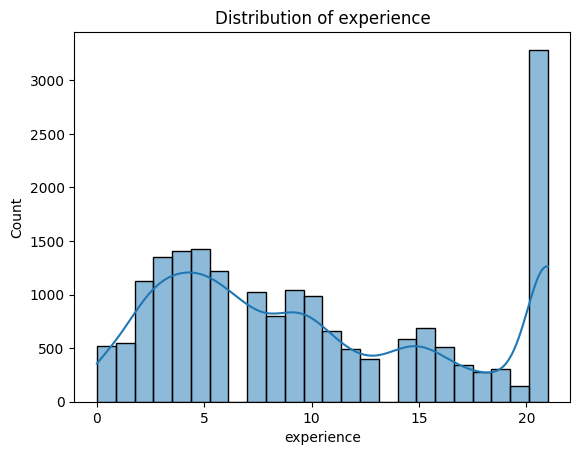

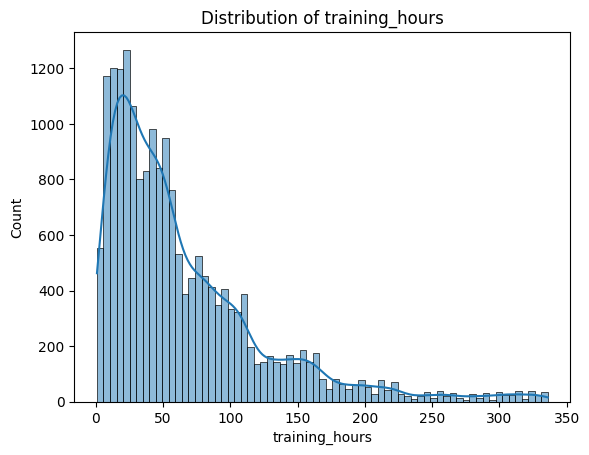

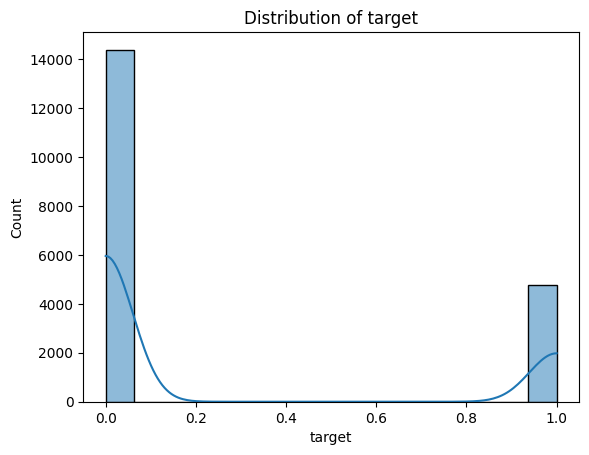

In [29]:
# Plot histograms for each numeric column
for column in df.select_dtypes(include=['float64', 'int64']).columns:
    sns.histplot(df[column], kde=True)
    plt.title(f"Distribution of {column}")
    plt.show()

<Axes: ylabel='gender'>

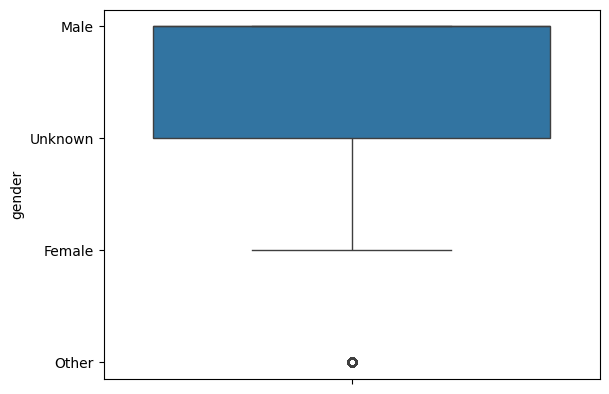

In [30]:
sns.boxplot(df['gender'])

There are few outliers in female and in others.

<Axes: xlabel='count', ylabel='gender'>

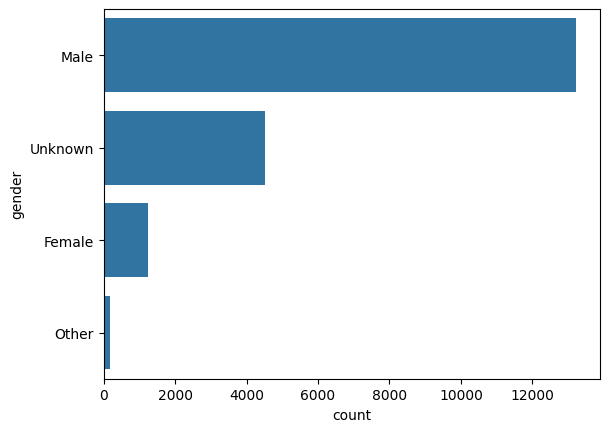

In [31]:
sns.countplot(df['gender'])

In [32]:
df['gender'].value_counts()

,count
gender,
Male,13221
Unknown,4508
Female,1238
Other,191


In [33]:
df.columns

Index(['enrollee_id', 'city', 'city_development_index', 'gender',
       'relevent_experience', 'enrolled_university', 'education_level',
       'major_discipline', 'experience', 'company_size', 'company_type',
       'last_new_job', 'training_hours', 'target'],
      dtype='object')

<Axes: xlabel='count', ylabel='relevent_experience'>

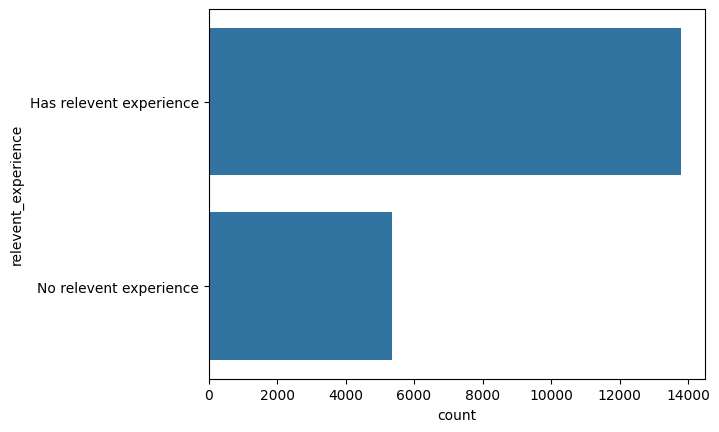

In [34]:
sns.countplot(df['relevent_experience'])

In [35]:
df['relevent_experience'].value_counts()

,count
relevent_experience,
Has relevent experience,13792
No relevent experience,5366


<Axes: ylabel='city_development_index'>

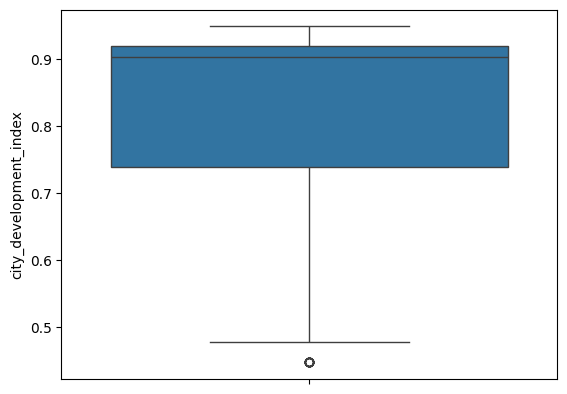

In [36]:
sns.boxplot(df['city_development_index'])

<Axes: ylabel='education_level'>

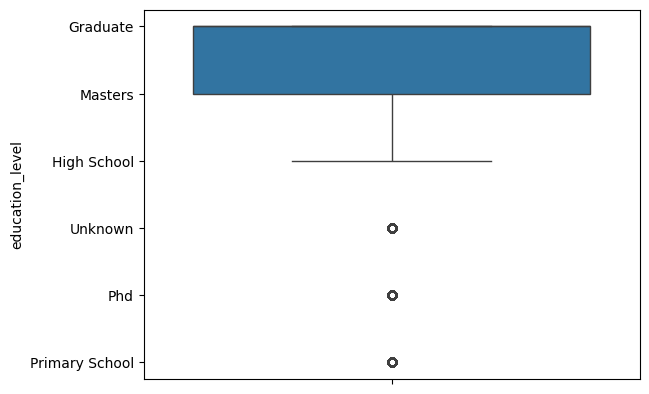

In [37]:
sns.boxplot(df['education_level'])

<Axes: xlabel='count', ylabel='education_level'>

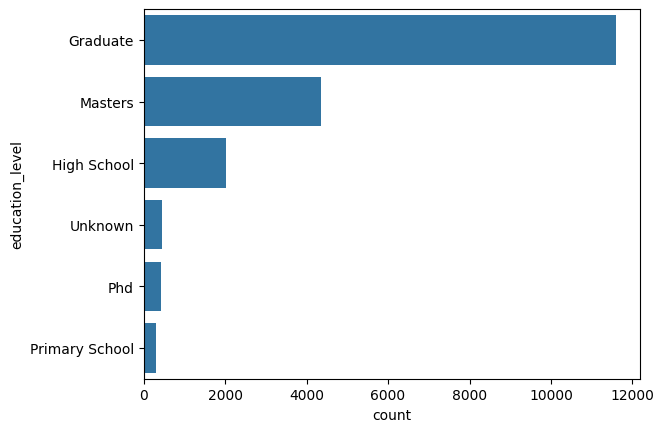

In [38]:
sns.countplot(df['education_level'])

In [39]:
df['education_level'].value_counts()

,count
education_level,
Graduate,11598
Masters,4361
High School,2017
Unknown,460
Phd,414
Primary School,308


<Axes: ylabel='major_discipline'>

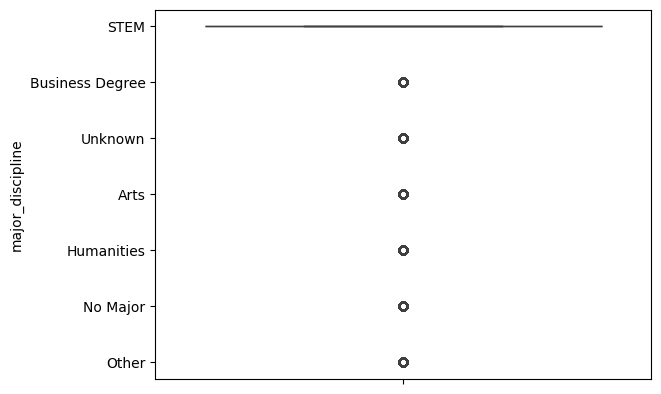

In [40]:
sns.boxplot(df['major_discipline'])

<Axes: xlabel='count', ylabel='major_discipline'>

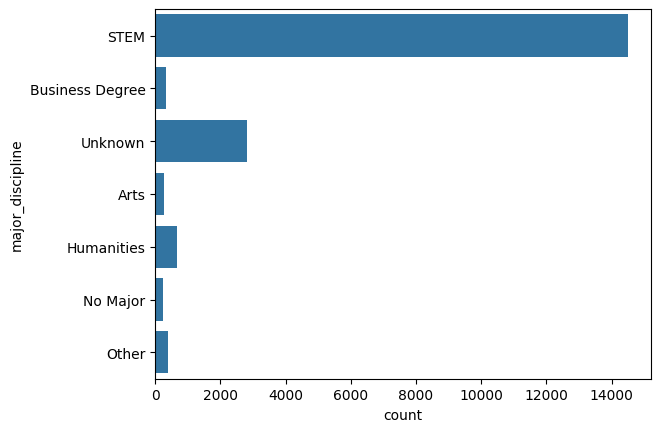

In [41]:
sns.countplot(df['major_discipline'])

In [42]:
df['major_discipline'].value_counts()

,count
major_discipline,
STEM,14492
Unknown,2813
Humanities,669
Other,381
Business Degree,327
Arts,253
No Major,223


<Axes: ylabel='experience'>

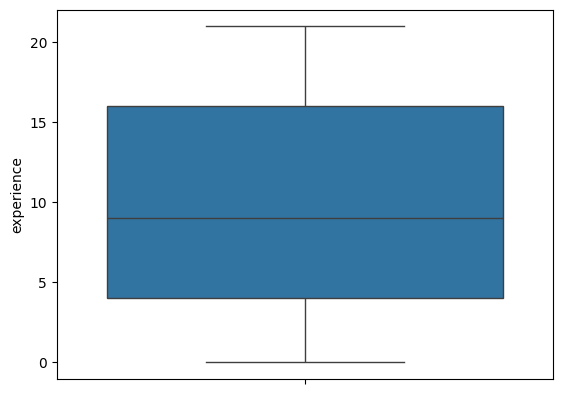

In [43]:
sns.boxplot(df['experience'])

In [44]:
# sns.countplot(df['experience'])

In [45]:
df['experience'].value_counts()

,count
experience,
21.0,3286
5.0,1430
4.0,1403
3.0,1354
6.0,1216
2.0,1127
9.0,1045
7.0,1028
10.0,985


<Axes: ylabel='company_size'>

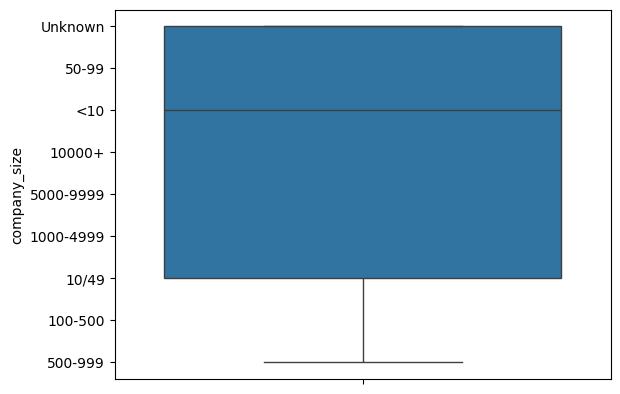

In [46]:
sns.boxplot(df['company_size'])

<Axes: xlabel='count', ylabel='company_size'>

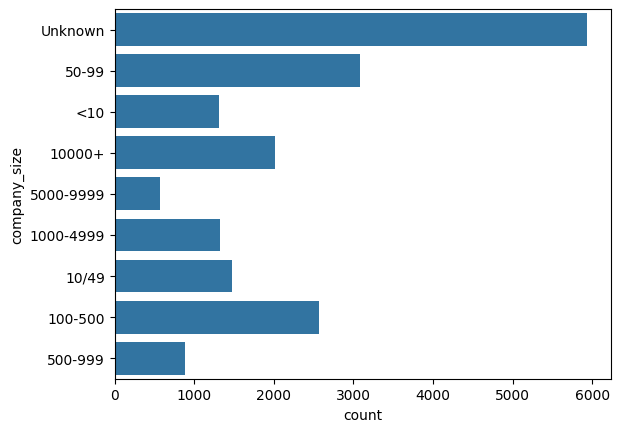

In [47]:
sns.countplot(df['company_size'])

In [48]:
df['company_size'].value_counts()

,count
company_size,
Unknown,5938
50-99,3083
100-500,2571
10000+,2019
10/49,1471
1000-4999,1328
<10,1308
500-999,877
5000-9999,563


<Axes: ylabel='company_type'>

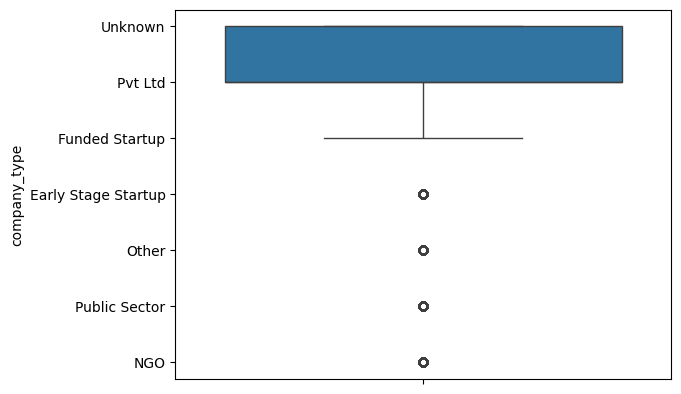

In [49]:
sns.boxplot(df['company_type'])

<Axes: xlabel='count', ylabel='company_type'>

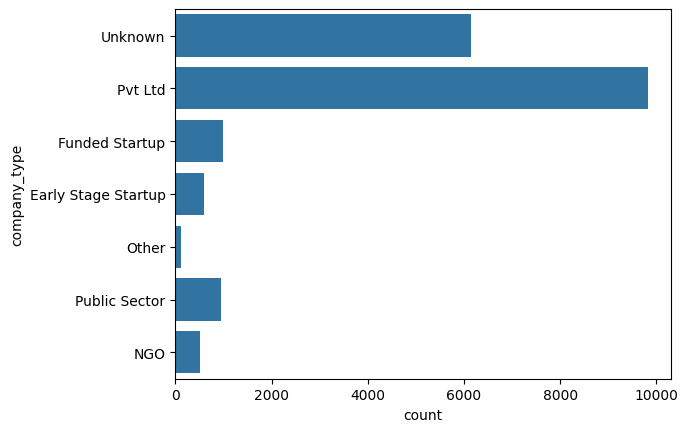

In [50]:
sns.countplot(df['company_type'])

In [51]:
df['company_type'].value_counts()

,count
company_type,
Pvt Ltd,9817
Unknown,6140
Funded Startup,1001
Public Sector,955
Early Stage Startup,603
NGO,521
Other,121


<Axes: ylabel='last_new_job'>

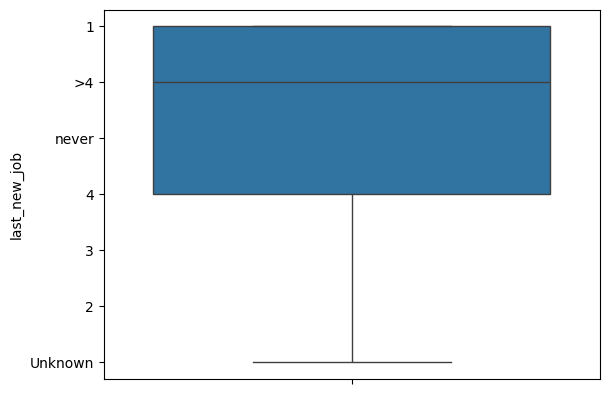

In [52]:
sns.boxplot(df['last_new_job'])

<Axes: xlabel='count', ylabel='last_new_job'>

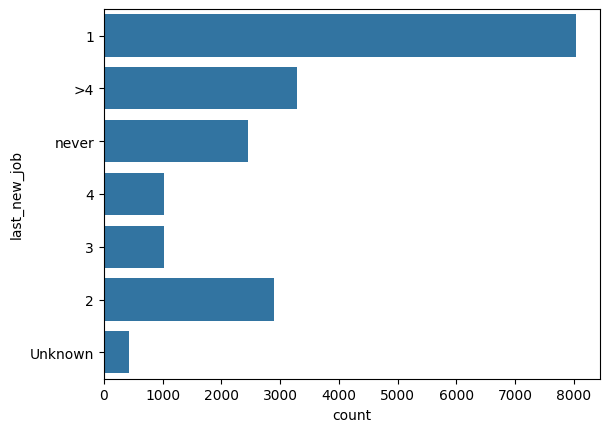

In [53]:
sns.countplot(df['last_new_job'])

In [54]:
df['last_new_job'].value_counts()

,count
last_new_job,
1,8040
>4,3290
2,2900
never,2452
4,1029
3,1024
Unknown,423


<Axes: ylabel='training_hours'>

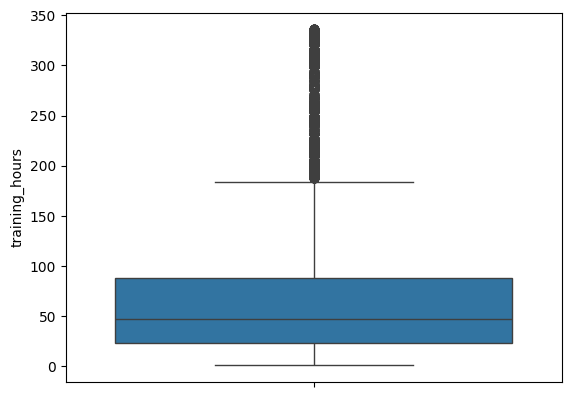

In [55]:
sns.boxplot(df['training_hours'])

<Axes: ylabel='target'>

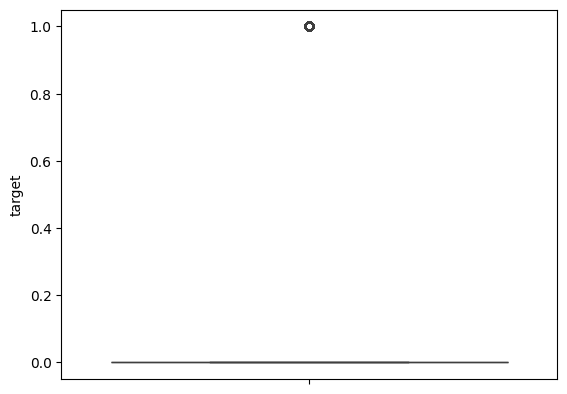

In [56]:
sns.boxplot(df['target'])

In [57]:
df['target'].value_counts()

,count
target,
0.0,14381
1.0,4777


#Preprocessing


In [58]:
from sklearn.preprocessing import LabelEncoder

In [59]:
le = LabelEncoder()

In [60]:
for i in df.columns:
  if df[i].dtype=='object':
    df[i]=le.fit_transform(df[i])

In [61]:
df

,enrollee_id,city,city_development_index,gender,relevent_experience,enrolled_university,education_level,major_discipline,experience,company_size,company_type,last_new_job,training_hours,target
0,8949,5,0.920,1,0,3,0,5,21.0,8,6,0,36,1.0
1,29725,77,0.776,1,1,3,0,5,15.0,4,5,4,47,0.0
2,11561,64,0.624,3,1,0,0,5,5.0,8,6,6,83,0.0
3,33241,14,0.789,3,1,2,0,1,0.0,8,5,6,52,1.0
4,666,50,0.767,1,0,3,2,5,21.0,4,1,3,8,0.0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
19153,7386,55,0.878,1,1,3,0,2,14.0,8,6,0,42,1.0
19154,31398,5,0.920,1,0,3,0,5,14.0,8,6,3,52,1.0
19155,24576,5,0.920,1,0,3,0,5,21.0,4,5,3,44,0.0
19156,5756,94,0.802,1,0,3,1,6,0.0,5,5,1,97,0.0


In [62]:
x = df.drop('target',axis=1)
y = df['target']

In [63]:
from sklearn.model_selection import train_test_split

In [64]:
x_train,x_test,y_train,y_test = train_test_split(x,y,test_size=0.2,random_state=123,stratify=y)

In [92]:
x_train

,enrollee_id,city,city_development_index,gender,relevent_experience,enrolled_university,education_level,major_discipline,experience,company_size,company_type,last_new_job,training_hours
14295,25474,5,0.920,1,0,0,1,6,6.0,8,2,1,36
635,6326,122,0.915,1,0,3,0,5,8.0,2,5,1,26
3449,9631,13,0.926,3,0,3,2,5,14.0,3,5,6,62
15531,7572,5,0.920,3,1,3,2,5,9.0,8,6,1,91
14781,27578,5,0.920,1,1,3,0,4,2.0,2,2,0,110
...,...,...,...,...,...,...,...,...,...,...,...,...,...
6423,4031,95,0.855,1,0,3,1,6,18.0,4,5,4,66
1860,27482,5,0.920,0,0,3,0,5,9.0,3,5,1,36
3027,22315,5,0.920,0,0,3,0,5,4.0,0,1,1,6
1251,26351,48,0.910,1,0,3,0,5,14.0,6,4,4,28


In [66]:
x_test

,enrollee_id,city,city_development_index,gender,relevent_experience,enrolled_university,education_level,major_discipline,experience,company_size,company_type,last_new_job,training_hours
17502,14330,14,0.789,1,1,0,0,5,5.0,4,5,6,17
9361,25809,5,0.920,1,0,3,0,5,18.0,2,5,3,23
11651,16988,49,0.920,1,0,3,3,5,10.0,8,4,0,48
15643,31601,5,0.920,1,0,3,0,5,21.0,3,5,0,166
15070,16550,13,0.926,1,0,3,2,5,20.0,3,5,4,64
...,...,...,...,...,...,...,...,...,...,...,...,...,...
16347,23182,67,0.698,3,0,3,0,5,6.0,4,5,0,204
60,29975,95,0.855,1,0,1,0,5,6.0,8,6,0,90
17788,4631,121,0.949,1,0,3,2,5,9.0,1,5,1,29
8268,2203,64,0.624,1,0,1,0,5,4.0,3,5,3,50


# Over sampling

In [67]:
from imblearn.over_sampling import SMOTE
sm = SMOTE()
x_os,y_os = sm.fit_resample(x_train,y_train)
x_os.shape
y_os.shape
y_os.value_counts()

,count
target,
1.0,11504
0.0,11504


#Model Selection

As the Dependent feature is Binary we have to use Classification algorithm

Logistic Regression
SVM
XG boost
Random Forest

# Logisctic regression

In [68]:
from sklearn.linear_model import LogisticRegression

In [69]:
logi = LogisticRegression()

In [70]:
logi.fit(x_os,y_os)

/usr/local/lib/python3.11/dist-packages/sklearn/linear_model/_logistic.py:465: ConvergenceWarning: lbfgs failed to converge (status=1):
STOP: TOTAL NO. OF ITERATIONS REACHED LIMIT.

Increase the number of iterations (max_iter) or scale the data as shown in:
    https://scikit-learn.org/stable/modules/preprocessing.html
Please also refer to the documentation for alternative solver options:
    https://scikit-learn.org/stable/modules/linear_model.html#logistic-regression
  n_iter_i = _check_optimize_result(


LogisticRegression()

we will use x_os insted of x_train because we have done under sampling

In [71]:
y_pred = logi.predict(x_test)

In [72]:
from sklearn.metrics import accuracy_score,confusion_matrix,classification_report

In [73]:
accuracy_score(y_pred,y_test)

0.6182150313152401

In [74]:
print(confusion_matrix(y_pred,y_test))

[[1738  324]
 [1139  631]]


In [75]:
print(classification_report(y_pred,y_test))

              precision    recall  f1-score   support

         0.0       0.60      0.84      0.70      2062
         1.0       0.66      0.36      0.46      1770

    accuracy                           0.62      3832
   macro avg       0.63      0.60      0.58      3832
weighted avg       0.63      0.62      0.59      3832



# XGBoost

In [76]:
from xgboost import  XGBClassifier

In [77]:
xgb = XGBClassifier()

In [78]:
param = {
    'learning_rate':[0.05,0.10,0.15,0.20,0.25,0.30],
       'max_depth':[3,4,5,6,8,10,12,15],
       'min_child_weight':[0.0,0.1,0.2,0.3,0.4],
       'n_estimator':[40,50,100]
}

In [79]:
from sklearn.model_selection import RandomizedSearchCV

In [80]:
rsc = RandomizedSearchCV(estimator=xgb,
                  param_distributions=param,
                random_state=42,
                   scoring='accuracy')

In [81]:
rsc.fit(x_os,y_os)

/usr/local/lib/python3.11/dist-packages/xgboost/core.py:158: UserWarning: [11:55:42] WARNING: /workspace/src/learner.cc:740: 
Parameters: { "n_estimator" } are not used.

  warnings.warn(smsg, UserWarning)
/usr/local/lib/python3.11/dist-packages/xgboost/core.py:158: UserWarning: [11:55:45] WARNING: /workspace/src/learner.cc:740: 
Parameters: { "n_estimator" } are not used.

  warnings.warn(smsg, UserWarning)
/usr/local/lib/python3.11/dist-packages/xgboost/core.py:158: UserWarning: [11:55:46] WARNING: /workspace/src/learner.cc:740: 
Parameters: { "n_estimator" } are not used.

  warnings.warn(smsg, UserWarning)
/usr/local/lib/python3.11/dist-packages/xgboost/core.py:158: UserWarning: [11:55:47] WARNING: /workspace/src/learner.cc:740: 
Parameters: { "n_estimator" } are not used.

  warnings.warn(smsg, UserWarning)
/usr/local/lib/python3.11/dist-packages/xgboost/core.py:158: UserWarning: [11:55:49] WARNING: /workspace/src/learner.cc:740: 
Parameters: { "n_estimator" } are not used.

  war

RandomizedSearchCV(estimator=XGBClassifier(base_score=None, booster=None,
                                           callbacks=None,
                                           colsample_bylevel=None,
                                           colsample_bynode=None,
                                           colsample_bytree=None, device=None,
                                           early_stopping_rounds=None,
                                           enable_categorical=False,
                                           eval_metric=None, feature_types=None,
                                           gamma=None, grow_policy=None,
                                           importance_type=None,
                                           interaction_constraints=None,
                                           learning_rate=None...
                                           min_child_weight=None, missing=nan,
                                           monotone_constraints=None,
                                           multi_strategy=None,
                                           n_estimators=None, n_jobs=None,
                                           num_parallel_tree=None,
                                           random_state=None, ...),
                   param_distributions={'learning_rate': [0.05, 0.1, 0.15, 0.2,
                                                          0.25, 0.3],
                                        'max_depth': [3, 4, 5, 6, 8, 10, 12,
                                                      15],
                                        'min_child_weight': [0.0, 0.1, 0.2, 0.3,
                                                             0.4],
                                        'n_estimator': [40, 50, 100]},
                   random_state=42, scoring='accuracy')

In [82]:
rsc.best_score_

np.float64(0.8291534604885792)

# Random Forest

In [83]:
from sklearn.ensemble import RandomForestClassifier

In [84]:
rf=RandomForestClassifier()

In [85]:
rf.fit(x_os,y_os)

RandomForestClassifier()

In [86]:
y_pred=rf.predict(x_test)

In [87]:
from sklearn.metrics import accuracy_score,confusion_matrix,classification_report

In [88]:
accuracy_score(y_test,y_pred)

0.7646137787056367

In [89]:
confusion_matrix(y_test,y_pred)

array([[2402,  475],
       [ 427,  528]])

In [90]:
print(classification_report(y_test,y_pred))

              precision    recall  f1-score   support

         0.0       0.85      0.83      0.84      2877
         1.0       0.53      0.55      0.54       955

    accuracy                           0.76      3832
   macro avg       0.69      0.69      0.69      3832
weighted avg       0.77      0.76      0.77      3832



# Conclusion

The best accuracy, among all three algorithms, is achieved by XGBoost Algorithm.